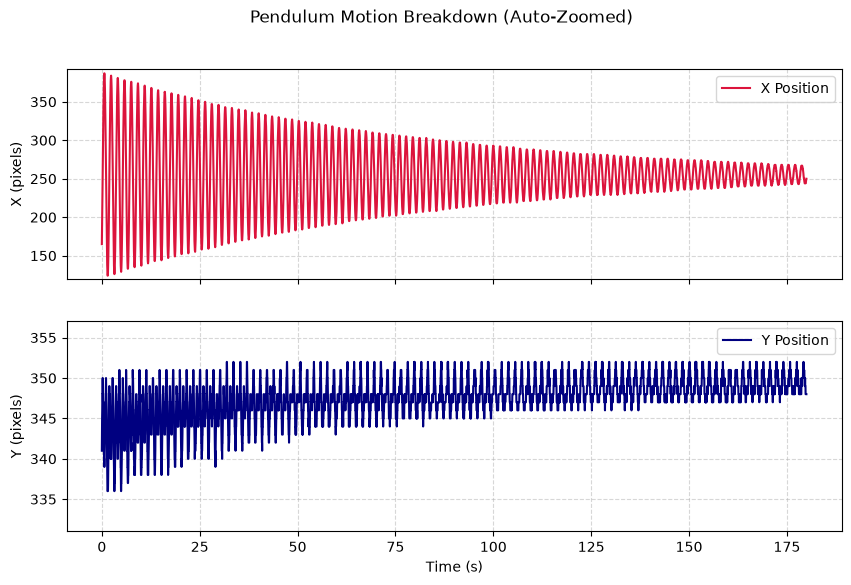

In [3]:
'''
Video-1
'''
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
file = pd.read_csv('/home/user/Desktop/Upload/results/video_1_trajectory.csv')
file = file[file["Time_s"] < 180]
file_2 = np.array(file)
# Mask valid rows
valid_mask = file_2[:, -1] > 0
times = file_2[valid_mask, 1]
x_coords = file_2[valid_mask, -2]
y_coords = file_2[valid_mask, -1]  # Assuming Y is the last column

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Plot X trajectory (Zoomed in)
ax1.plot(times, x_coords, color="crimson", label="X Position")
ax1.set_ylabel("X (pixels)")
ax1.set_ylim(np.min(x_coords) - 5, np.max(x_coords) + 5)  # Auto-zoom
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# Plot Y trajectory (Zoomed in)
ax2.plot(times, y_coords, color="navy", label="Y Position")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Y (pixels)")
ax2.set_ylim(np.min(y_coords) - 5, np.max(y_coords) + 5)  # Auto-zoom
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.suptitle("Pendulum Motion Breakdown (Auto-Zoomed)")
plt.show()

In [5]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks

# 1. Load your data

# 2. Shift the data to oscillate around 0 instead of 250
baseline = 250
y_shifted = y - baseline

# 3. Find the real peaks now that the data is centered
# We set distance to skip rows so it only grabs the true peak of each swing
# (Adjust distance based on how many rows are in one 2.5-second swing)
peak_indices, _ = find_peaks(y_shifted, distance=50, prominence=5)

# 4. Extract the top two peaks
t1, y1 = t[peak_indices[0]], y_shifted[peak_indices[0]]
t2, y2 = t[peak_indices[1]], y_shifted[peak_indices[1]]

# 5. Calculate gamma using the true shifted amplitudes
gamma = np.log(y1 / y2) / (t2 - t1)

print(f"Real Peak 1 (Shifted): t = {t1:.3f}, Amplitude = {y1:.3f}")
print(f"Real Peak 2 (Shifted): t = {t2:.3f}, Amplitude = {y2:.3f}")
print(f"Calculated Damping Constant (gamma): {gamma:.4f}")


Real Peak 1 (Shifted): t = 0.633, Amplitude = 137.000
Real Peak 2 (Shifted): t = 2.366, Amplitude = 134.000
Calculated Damping Constant (gamma): 0.0128


In [6]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks

# 1. Load data
df = pd.read_csv('/home/user/Desktop/Upload/results/video_1_trajectory.csv')
t = df.iloc[:, 1].values
y = df.iloc[:, 2].values

# 2. Baseline shift (centered around 250)
baseline = 250
y_shifted = y - baseline

# 3. Find ALL peaks across the entire file
# Adjust distance if it skips peaks or catches double peaks on a single swing
peak_indices, _ = find_peaks(y_shifted, distance=50, prominence=5)

t_peaks = t[peak_indices]
amp_peaks = y_shifted[peak_indices]

print(f"=== DETECTED {len(t_peaks)} PEAKS. STARTING CONTINUOUS TRACKING ===\n")
print(f"{'Peak #':<8}{'Time (s)':<12}{'Amplitude':<14}{'Interval Gamma':<16}{'Cumulative Gamma':<16}")
print("-" * 66)

gammas = []

# Loop through all found peaks to track the decay continuously
for i in range(len(t_peaks)):
    if i == 0:
        # First point serves as our baseline starting anchor
        print(f"{i+1:<8}{t_peaks[i]:<12.3f}{amp_peaks[i]:<14.3f}{'-':<16}{'-':<16}")
    else:
        # 4. Interval Gamma (compared to the immediate previous peak)
        dt_interval = t_peaks[i] - t_peaks[i-1]
        # Max check to avoid division by zero or log of negative numbers if noise hits
        if amp_peaks[i-1] > 0 and amp_peaks[i] > 0:
            gamma_interval = np.log(amp_peaks[i-1] / amp_peaks[i]) / dt_interval
        else:
            gamma_interval = np.nan
            
        # 5. Cumulative Gamma (compared all the way back to Peak 1 for stability)
        dt_cumulative = t_peaks[i] - t_peaks[0]
        gamma_cumulative = np.log(amp_peaks[0] / amp_peaks[i]) / dt_cumulative
        
        gammas.append(gamma_cumulative)
        
        print(f"{i+1:<8}{t_peaks[i]:<12.3f}{amp_peaks[i]:<14.3f}{gamma_interval:<16.4f}{gamma_cumulative:<16.4f}")

print("\n" + "="*50)
print(f"Tracking Complete!")
print(f"Overall Best-Fit Damping Constant (γ): {np.nanmean(gammas):.4f}")
print("="*50)


=== DETECTED 149 PEAKS. STARTING CONTINUOUS TRACKING ===

Peak #  Time (s)    Amplitude     Interval Gamma  Cumulative Gamma
------------------------------------------------------------------
1       0.633       137.000       -               -               
2       2.366       134.000       0.0128          0.0128          
3       4.065       131.000       0.0133          0.0130          
4       5.765       128.000       0.0136          0.0132          
5       7.497       126.000       0.0091          0.0122          
6       9.230       124.000       0.0092          0.0116          
7       10.929      121.000       0.0144          0.0121          
8       12.629      118.000       0.0148          0.0124          
9       14.361      115.000       0.0149          0.0128          
10      16.061      113.000       0.0103          0.0125          
11      17.794      111.000       0.0103          0.0123          
12      19.493      109.000       0.0107          0.0121          
13  

In [9]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks

# 1. Load data
df = pd.read_csv('/home/abhishek.singh/Desktop/Upload/results/video_3_trajectory.csv')
t = df.iloc[:, 1].values
y = df.iloc[:, 2].values
# Find positive peaks (crests)
peaks, _ = find_peaks(y, distance=50, prominence=5)
# Find negative peaks (valleys) by flipping the data upside down
valleys, _ = find_peaks(-y, distance=50, prominence=5)

# Match them up to find the true dynamic center
min_len = min(len(peaks), len(valleys))
baselines = []

for i in range(min_len):
    # The center level during this specific oscillation cycle
    cycle_center = (y[peaks[i]] + y[valleys[i]]) / 2
    baselines.append(cycle_center)

true_baseline = np.mean(baselines)
print(f"Automatically determined baseline for this video: {true_baseline:.3f}")


Automatically determined baseline for this video: 205.419


In [10]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks

# 1. Load your data
# 1. Load data
df = pd.read_csv('/home/abhishek.singh/Desktop/Upload/results/video_3_trajectory.csv')
t = df.iloc[:, 1].values
y = df.iloc[:, 2].values

# 2. Find all macro crests and troughs across the data stream
# Adjust 'distance' based on your 30fps rate if it double-counts a single swing
crests, _ = find_peaks(y, distance=50, prominence=5)
troughs, _ = find_peaks(-y, distance=50, prominence=5)

print(f"=== SENSOR CONFIGURATION ===")
print(f"Detected Crests: {len(crests)} | Detected Troughs: {len(troughs)}")
print(f"===============================================================\n")

print(f"{'Peak #':<8}{'Time (s)':<12}{'Raw Y':<10}{'Local Center':<16}{'True Amp':<12}{'Cum. Gamma':<12}")
print("-" * 72)

gammas = []
first_valid_amplitude = None
first_valid_time = None

# Set window size (3 means it averages the 3 closest crests and 3 closest troughs)
WINDOW_SIZE = 3

# 3. Track dynamically peak-by-peak
for i, c_idx in enumerate(crests):
    # Find the nearest neighboring crests and troughs for our moving window
    # This prevents edge errors at the very start or end of the video
    c_start = max(0, i - WINDOW_SIZE // 2)
    c_end = min(len(crests), c_start + WINDOW_SIZE)
    
    # Target matching troughs in the same timeline
    t_start = max(0, min(i, len(troughs) - WINDOW_SIZE))
    t_end = min(len(troughs), t_start + WINDOW_SIZE)
    
    # Calculate the localized baseline across the window
    mean_crest = np.mean(y[crests[c_start:c_end]])
    mean_trough = np.mean(y[troughs[t_start:t_end]])
    local_baseline = (mean_crest + mean_trough) / 2
    
    # Extract the absolute true amplitude for this specific swing
    amplitude = y[c_idx] - local_baseline
    time_val = t[c_idx]
    
    # Filter out edge anomalies or dead oscillations
    if amplitude <= 0:
        continue
        
    if first_valid_amplitude is None:
        # Establish the true starting anchor point
        first_valid_amplitude = amplitude
        first_valid_time = time_val
        print(f"{i+1:<8}{time_val:<12.3f}{y[c_idx]:<10.1f}{local_baseline:<16.3f}{amplitude:<12.3f}{'-':<12}")
    else:
        # Calculate stable Cumulative Gamma anchored back to our starting frame
        dt = time_val - first_valid_time
        gamma_cumulative = np.log(first_valid_amplitude / amplitude) / dt
        gammas.append(gamma_cumulative)
        
        print(f"{i+1:<8}{time_val:<12.3f}{y[c_idx]:<10.1f}{local_baseline:<16.3f}{amplitude:<12.3f}{gamma_cumulative:<12.4f}")

print("\n" + "=" * 50)
print(f"Dynamic Window Tracking Complete!")
print(f"Robust System Damping Constant (γ): {np.nanmean(gammas):.4f}")
print("=" * 50)


=== SENSOR CONFIGURATION ===
Detected Crests: 131 | Detected Troughs: 130

Peak #  Time (s)    Raw Y     Local Center    True Amp    Cum. Gamma  
------------------------------------------------------------------------
1       1.667       302.0     208.667         93.333      -           
2       3.367       300.0     209.500         90.500      0.0181      
3       5.067       298.0     209.667         88.333      0.0162      
4       6.734       296.0     209.667         86.333      0.0154      
5       8.467       294.0     209.500         84.500      0.0146      
6       10.167      292.0     209.000         83.000      0.0138      
7       11.867      290.0     208.667         81.333      0.0135      
8       13.568      288.0     208.667         79.333      0.0137      
9       15.301      287.0     208.833         78.167      0.0130      
10      17.001      285.0     208.833         76.167      0.0133      
11      18.735      284.0     208.500         75.500      0.0124      


In [5]:
import os
import glob
import pandas as pd
import numpy as np
from scipy.signal import find_peaks

data_folder = '/home/user/Desktop/Upload/results' 
csv_files = glob.glob(os.path.join(data_folder, '*.csv'))
summary_results = []

print(f"Found {len(csv_files)} CSV files to process.\n")
print(f"{'File Name':<30}{'Peaks Found':<15}{'Static Baseline':<18}{'Final Gamma (γ)':<15}")
print("-" * 78)

for file_path in csv_files:
    file_name = os.path.basename(file_path)
    if file_name == 'pendulum_damping_summary.csv':
        continue
        
    try:
        df = pd.read_csv(file_path)
        
        # Clean text anomalies (Fix for Video 2)
        t = pd.to_numeric(df.iloc[:, 1], errors='coerce').values
        y = pd.to_numeric(df.iloc[:, 2], errors='coerce').values
        
        valid_mask = ~np.isnan(t) & ~np.isnan(y)
        t = t[valid_mask]
        y = y[valid_mask]
        
        # Find peaks with standard threshold
        crests, _ = find_peaks(y, distance=45, prominence=5)
        troughs, _ = find_peaks(-y, distance=45, prominence=5)

        if len(crests) < 3 or len(troughs) < 3:
            print(f"{file_name:<30}{len(crests):<15}{'Insufficient Peaks':<18}{'-':<15}")
            continue
            
        # The correct, original baseline subtraction method
        global_baseline = (np.mean(y[crests]) + np.mean(y[troughs])) / 2
        amplitudes = y[crests] - global_baseline  # Back to original math!
        times = t[crests]
        
        first_amp = amplitudes[0]
        first_time = times[0]
        
        file_gammas = []
        for i in range(1, len(amplitudes)):
            if amplitudes[i] > 0:
                dt = times[i] - first_time
                gamma_cumulative = np.log(first_amp / amplitudes[i]) / dt
                file_gammas.append(gamma_cumulative)
        
        # Calculate the stable average tail
        stable_gammas = file_gammas[len(file_gammas)//2:]
        final_gamma = np.mean(stable_gammas) if len(stable_gammas) > 0 else np.nan
        
        summary_results.append({
            'File Name': file_name, 'Total Peaks': len(crests),
            'Baseline': round(global_baseline, 3), 'Gamma': round(final_gamma, 4)
        })
        
        print(f"{file_name:<30}{len(crests):<15}{global_baseline:<18.3f}{final_gamma:<15.4f}")
        
    except Exception as e:
        print(f"Error processing {file_name}: {str(e)}")

summary_df = pd.DataFrame(summary_results)
summary_df.to_csv('pendulum_damping_summary.csv', index=False)
print("\n" + "="*50)
print("Batch Processing Fixed & Complete!")
print("="*50)


Found 9 CSV files to process.

File Name                     Peaks Found    Static Baseline   Final Gamma (γ)
------------------------------------------------------------------------------
video_3_trajectory.csv        133            205.380           0.0121         
video_1_trajectory.csv        153            248.944           0.0110         
video_2_trajectory.csv        157            278.557           0.0109         
video_4_trajectory.csv        79             229.591           0.0242         
video_5_trajectory.csv        77             265.741           0.0243         
video_6_trajectory.csv        77             334.330           0.0238         
video_9_trajectory.csv        7              225.714           0.2478         
video_7_trajectory.csv        10             230.500           0.2320         
video_8_trajectory.csv        7              225.857           0.2560         

Batch Processing Fixed & Complete!


1       1.706       195.000       -               -               
1       1.706       195.000       -               -               
1       1.706       195.000       -               -               


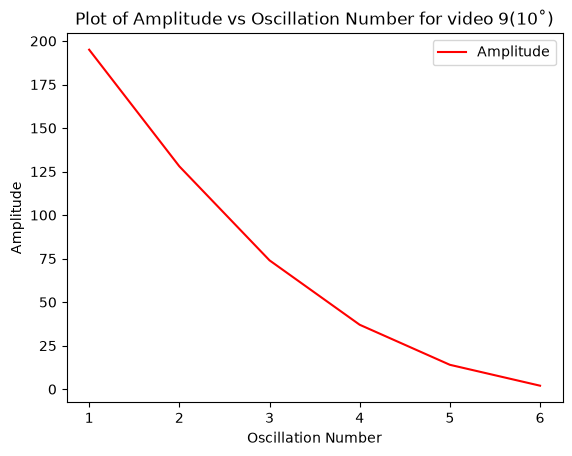

In [28]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks


def batch(file):
# 1. Load data
    df = pd.read_csv(str(file))
    t = df.iloc[:, 1].values
    y = df.iloc[:, 2].values

# 2. Baseline shift (centered around 250)
    baseline = 250
    y_shifted = y - baseline

# 3. Find ALL peaks across the entire file
# Adjust distance if it skips peaks or catches double peaks on a single swing
    peak_indices, _ = find_peaks(y_shifted, distance=50, prominence=5)

    t_peaks = t[peak_indices]
    amp_peaks = y_shifted[peak_indices]
    gammas = []

# Loop through all found peaks to track the decay continuously
    for i in range(len(t_peaks)):
        if i == 0:
        # First point serves as our baseline starting anchor
            print(f"{i+1:<8}{t_peaks[i]:<12.3f}{amp_peaks[i]:<14.3f}{'-':<16}{'-':<16}")
        else:
        # 4. Interval Gamma (compared to the immediate previous peak)
            dt_interval = t_peaks[i] - t_peaks[i-1]
        # Max check to avoid division by zero or log of negative numbers if noise hits
            if amp_peaks[i-1] > 0 and amp_peaks[i] > 0:
                gamma_interval = np.log(amp_peaks[i-1] / amp_peaks[i]) / dt_interval
            else:
                gamma_interval = np.nan
            
        # 5. Cumulative Gamma (compared all the way back to Peak 1 for stability)
            dt_cumulative = t_peaks[i] - t_peaks[0]
            gamma_cumulative = np.log(amp_peaks[0] / amp_peaks[i]) / dt_cumulative
        
            gammas.append(gamma_cumulative)
        return amp_peaks
        #print(f"{i+1:<8}{t_peaks[i]:<12.3f}{amp_peaks[i]:<14.3f}{gamma_interval:<16.4f}{gamma_cumulative:<16.4f}")

#print("\n" + "="*50)
#print(f"Tracking Complete!")
#print(f"Overall Best-Fit Damping Constant (γ): {np.nanmean(gammas):.4f}")
#print("="*50)

from matplotlib import pyplot as plt
file = '/home/user/Desktop/Upload/results/video_9_trajectory.csv'
n = np.arange(1, len(batch(file)))
#plt.scatter(n, amp_peaks[0:148], color='red')
plt.plot(n, batch(file)[0:len(batch(file))-1], color='red', label='Amplitude')
plt.title('Plot of Amplitude vs Oscillation Number for video 9(10˚)')
plt.xlabel('Oscillation Number')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

In [3]:
import os
import cv2

# 1. Video Path & Setup
video_path = "/home/user/Desktop/Videos/video_11.mp4"  # Replace with the video that failed
output_dir = "./extracted_frames"
os.makedirs(output_dir, exist_ok=True)

cap = cv2.VideoCapture(video_path)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if total_frames <= 0:
    print("Could not read video frames. Check your video path.")
else:
    # 2. Calculate frame indices to sample evenly across the video
    num_frames_to_extract = 10
    frame_indices = [
        int(i * (total_frames - 1) / (num_frames_to_extract - 1))
        for i in range(num_frames_to_extract)
    ]

    print(
        f"Extracting {num_frames_to_extract} frames from total {total_frames} frames..."
    )

    # 3. Extract and save frames
    for idx, frame_no in enumerate(frame_indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no)
        ret, frame = cap.read()

        if ret and frame is not None:
            save_path = os.path.join(
                output_dir, f"frame_{idx + 1}_at_idx_{frame_no}.jpg"
            )
            cv2.imwrite(save_path, frame)
            print(f"Saved: {save_path}")

    cap.release()
    print("Done! Check the './extracted_frames' folder.")

Extracting 10 frames from total 375 frames...
Saved: ./extracted_frames/frame_1_at_idx_0.jpg
Saved: ./extracted_frames/frame_2_at_idx_41.jpg
Saved: ./extracted_frames/frame_3_at_idx_83.jpg
Saved: ./extracted_frames/frame_4_at_idx_124.jpg
Saved: ./extracted_frames/frame_5_at_idx_166.jpg
Saved: ./extracted_frames/frame_6_at_idx_207.jpg
Saved: ./extracted_frames/frame_7_at_idx_249.jpg
Saved: ./extracted_frames/frame_8_at_idx_290.jpg
Saved: ./extracted_frames/frame_9_at_idx_332.jpg
Saved: ./extracted_frames/frame_10_at_idx_374.jpg
Done! Check the './extracted_frames' folder.
